# 05 — Huấn luyện, Đánh giá và Trích xuất Embedding: Mô hình SASRec

Notebook này thực hiện trọn vẹn quy trình huấn luyện và đánh giá mô hình **SASRec** (*Self-Attentive Sequential Recommendation — Kang & McAuley, ICDM 2018*) trên bộ dữ liệu **Diginetica** với **2 random seed (`2024`, `2025`)**.

## Đặc trưng kiến trúc của SASRec và Giao thức thí nghiệm

1. **Kiến trúc Causal Multi-Head Self-Attention (Transformer):**
   - Kết hợp `item_embedding` và `position_embedding` (`max_seq_length = 50`), đi qua `LayerNorm` và `Dropout`.
   - Đi qua `n_layers = 2` khối Transformer với mặt nạ nhân quả (**Causal Mask** — vị trí $t$ chỉ được nhìn các vị trí $\le t$) và Point-wise Feed-Forward (`inner_size = 256`, hàm kích hoạt `GELU`).
   - Lấy vector biểu diễn tại vị trí cuối thực tế của phiên nhân vô hướng với toàn bộ bảng `item_embedding`.
2. **Đảm bảo tính công bằng tuyệt đối với GRU4Rec và NARM:**
   - Dùng chung tập `train_examples.parquet`, `validation_examples.parquet`, `test_examples.parquet`, `item_mapping.csv`.
   - Khóa cứng gradient và mask điểm (`-1e9`) đối với `padding_idx = 0` và `7.647` Controlled Cold items.
   - Lưu ý khi trích xuất embedding: Chỉ trích xuất đúng `model.item_embedding.weight[1:]` (`37.583` hàng), tuyệt đối không nhầm với `position_embedding`.
   - Xuất đủ 8 file chuẩn vào `runs/sasrec/seed_{2024,2025}/` và bảng cấp độ item vào `results/item_level/sasrec_seed{2024,2025}.parquet`.

In [1]:
# ========================================================================
# 0. Cài đặt môi trường làm việc trên Kaggle GPU
# ========================================================================
import os
import shutil
import sys
from pathlib import Path

if Path('/kaggle/input').exists():
    print('[Kaggle Environment Detected]')
    print('Contents of /kaggle/input:', list(Path('/kaggle/input').iterdir()))
    source_dir = None
    for p in Path('/kaggle/input').rglob('BTL-K03-tong-quan-de-tai.md'):
        source_dir = p.parent
        break
    if source_dir is not None:
        print(f'Nguồn dự án tìm thấy tại: {source_dir}')
        working_dir = Path('/kaggle/working')
        for item in source_dir.iterdir():
            target = working_dir / item.name
            if item.is_dir():
                shutil.copytree(item, target, dirs_exist_ok=True)
            else:
                shutil.copy2(item, target)
        os.chdir(str(working_dir))
        print(f'Thư mục làm việc hiện tại: {Path.cwd()}')
        print('Danh sách tệp tại working dir:', [p.name for p in Path.cwd().iterdir()])
    else:
        raise FileNotFoundError('Không tìm thấy BTL-K03-tong-quan-de-tai.md trong /kaggle/input!')
else:
    print('[Local Environment] Chạy trên thư mục cục bộ.')


[Kaggle Environment Detected]
Contents of /kaggle/input: [PosixPath('/kaggle/input/datasets')]
Nguồn dự án tìm thấy tại: /kaggle/input/datasets/ngytfd/btl-k03-sasrec-data
Thư mục làm việc hiện tại: /kaggle/working
Danh sách tệp tại working dir: ['__notebook__.ipynb', 'configs', 'data', 'BTL-K03-tong-quan-de-tai.md', 'src']


## 1. Thiết lập môi trường, thiết bị (GPU/CPU) và đọc cấu hình

In [2]:
from pathlib import Path
import json
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "BTL-K03-tong-quan-de-tai.md").exists():
            return candidate
    raise FileNotFoundError("Không tìm thấy thư mục gốc dự án BTL-K03.")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from btl_k03.paths import FIGURES_DIR, ITEM_LEVEL_DIR, PROCESSED_DIGI_DIR, RUNS_DIR, TABLES_DIR, ensure_output_dirs
from btl_k03.utils import load_experiment_config, load_item_mapping, set_global_seed
from btl_k03.models import SessionPrefixDataset, build_model_from_config, train_and_evaluate_seed

ensure_output_dirs()

MODEL_NAME = "sasrec"
CONFIG = load_experiment_config(MODEL_NAME)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Python executable : {sys.executable}")
print(f"PyTorch version   : {torch.__version__}")
print(f"Device            : {DEVICE} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
print(f"Model architecture: {CONFIG['architecture']}")
print(f"Seeds             : {CONFIG['seeds']}")
print(f"Model params      : {json.dumps(CONFIG['model_params'], ensure_ascii=False)}")
print(f"Training config   : {json.dumps(CONFIG['training'], ensure_ascii=False)}")

Python executable : /usr/bin/python3
PyTorch version   : 2.11.0+cu128
Device            : cuda (Tesla T4)
Model architecture: SASRec
Seeds             : [2024, 2025]
Model params      : {"embedding_size": 64, "n_layers": 2, "n_heads": 2, "inner_size": 256, "hidden_dropout_prob": 0.2, "attn_dropout_prob": 0.2, "hidden_act": "gelu", "layer_norm_eps": 1e-12, "initializer_range": 0.02}
Training config   : {"loss_type": "CE", "optimizer": "adam", "learning_rate": 0.001, "weight_decay": 0.0, "grad_clip_norm": 5.0, "train_batch_size": 512, "eval_batch_size": 1024, "epochs": 30, "num_workers": 0, "pin_memory": true, "use_amp": false}


## 2. Kiểm tra dữ liệu đầu vào và mặt nạ Warm / Controlled Cold (`Option B`)

In [3]:
item_mapping = load_item_mapping(PROCESSED_DIGI_DIR)
train_examples = pd.read_parquet(PROCESSED_DIGI_DIR / "train_examples.parquet")
val_examples = pd.read_parquet(PROCESSED_DIGI_DIR / "validation_examples.parquet")
test_examples = pd.read_parquet(PROCESSED_DIGI_DIR / "test_examples.parquet")
test_last_examples = pd.read_parquet(PROCESSED_DIGI_DIR / "test_last_item_examples.parquet")

n_total_catalog = len(item_mapping)
n_warm = int(item_mapping["is_trainable_warm"].sum())
n_cold = int(item_mapping["is_controlled_cold"].sum())

summary_input = pd.DataFrame([
    {"Chỉ tiêu": "Tổng số item trong bảng Embedding (ID 1..N)", "Giá trị": f"{n_total_catalog:,}"},
    {"Chỉ tiêu": "Số item Warm hợp lệ (is_trainable_warm = True)", "Giá trị": f"{n_warm:,}"},
    {"Chỉ tiêu": "Số item Controlled Cold 20% (is_controlled_cold = True)", "Giá trị": f"{n_cold:,}"},
    {"Chỉ tiêu": "Số mẫu Train (All-prefix)", "Giá trị": f"{len(train_examples):,}"},
    {"Chỉ tiêu": "Số mẫu Validation Warm (All-prefix)", "Giá trị": f"{len(val_examples):,}"},
    {"Chỉ tiêu": "Số mẫu Test Warm chính (All-prefix)", "Giá trị": f"{len(test_examples):,}"},
    {"Chỉ tiêu": "Số mẫu Test Warm phiên cuối (Last-item)", "Giá trị": f"{len(test_last_examples):,}"},
])
display(summary_input)

,Chỉ tiêu,Giá trị
0,Tổng số item trong bảng Embedding (ID 1..N),"37,583"
1,Số item Warm hợp lệ (is_trainable_warm = True),"29,936"
2,Số item Controlled Cold 20% (is_controlled_col...,"7,647"
3,Số mẫu Train (All-prefix),"498,849"
4,Số mẫu Validation Warm (All-prefix),"29,828"
5,Số mẫu Test Warm chính (All-prefix),"40,001"
6,Số mẫu Test Warm phiên cuối (Last-item),"12,791"


## 3. Khởi tạo kiến trúc SASRec và Sanity Check khóa Gradient Cold Item

In [4]:
set_global_seed(2024)
sanity_model = build_model_from_config(CONFIG, item_mapping, DEVICE)
print(sanity_model)

sample_ds = SessionPrefixDataset(train_examples.head(64), max_seq_length=CONFIG["max_seq_length"])
sample_seq = sample_ds.sequences.to(DEVICE)
sample_len = sample_ds.lengths.to(DEVICE)
sample_target = sample_ds.targets_tensor.to(DEVICE)

sanity_model.zero_grad()
logits = sanity_model.full_sort_logits(sample_seq, sample_len, mask_cold_and_pad=True)
loss = torch.nn.functional.cross_entropy(logits, sample_target)
loss.backward()

grad_matrix = sanity_model.item_embedding.weight.grad.detach().cpu().numpy()
cold_ids = item_mapping.loc[item_mapping["is_controlled_cold"], "internal_item_id"].to_numpy()
warm_ids = item_mapping.loc[item_mapping["is_trainable_warm"], "internal_item_id"].to_numpy()

max_cold_grad = float(np.max(np.abs(grad_matrix[cold_ids])))
max_pad_grad = float(np.max(np.abs(grad_matrix[0])))
max_warm_grad = float(np.max(np.abs(grad_matrix[warm_ids])))

print(f"\n[SANITY CHECK GRADIENT - SASRec]")
print(f"- Loss khởi tạo (Cross-Entropy trên 29,936 warm items): {loss.item():.4f} (Lý thuyết ~ ln(29936) = {np.log(n_warm):.4f})")
print(f"- Max |grad| của hàng Padding (ID 0)                  : {max_pad_grad:.10f}")
print(f"- Max |grad| của 7,647 hàng Controlled Cold           : {max_cold_grad:.10f}")
print(f"- Max |grad| của 29,936 hàng Trainable Warm           : {max_warm_grad:.10f}")
assert max_cold_grad == 0.0 and max_pad_grad == 0.0 and max_warm_grad > 0.0
del sanity_model

SASRecModel(
  (item_embedding): Embedding(37584, 64, padding_idx=0)
  (position_embedding): Embedding(50, 64)
  (layer_norm): LayerNorm((64,), eps=1e-12, elementwise_affine=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (blocks): ModuleList(
    (0-1): 2 x SASRecTransformerBlock(
      (query): Linear(in_features=64, out_features=64, bias=True)
      (key): Linear(in_features=64, out_features=64, bias=True)
      (value): Linear(in_features=64, out_features=64, bias=True)
      (attn_dropout): Dropout(p=0.2, inplace=False)
      (out_proj): Linear(in_features=64, out_features=64, bias=True)
      (out_dropout): Dropout(p=0.2, inplace=False)
      (layer_norm_1): LayerNorm((64,), eps=1e-12, elementwise_affine=True)
      (ffn_1): Linear(in_features=64, out_features=256, bias=True)
      (ffn_2): Linear(in_features=256, out_features=64, bias=True)
      (ffn_dropout): Dropout(p=0.2, inplace=False)
      (layer_norm_2): LayerNorm((64,), eps=1e-12, elementwise_affine=True)
    )
  )
)

## 4. Huấn luyện SASRec trên 2 Seed (`2024` và `2025`)

In [5]:
MAX_EPOCHS_OVERRIDE = None  # Đặt bằng None để chạy full theo config (30 epochs + Early Stopping)

run_outputs = {}
for seed in CONFIG["seeds"]:
    run_outputs[seed] = train_and_evaluate_seed(
        model_name=MODEL_NAME,
        seed=seed,
        config=CONFIG,
        processed_dir=PROCESSED_DIGI_DIR,
        max_epochs_override=MAX_EPOCHS_OVERRIDE,
    )

2026-10-25 13:28:02 | INFO | ========================================================================
2026-10-25 13:28:02 | INFO | BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH SASREC | SEED = 2024
2026-10-25 13:28:02 | INFO | Thiết bị chạy (Device) : cuda
2026-10-25 13:28:02 | INFO | Thư mục lưu kết quả    : /kaggle/working/runs/sasrec/seed_2024
2026-10-25 13:28:02 | INFO | ========================================================================
2026-10-25 13:28:03 | INFO | Tổng số item trong bảng Embedding: 37,583 (+1 hàng padding 0) | Warm trainable: 29,936 | Controlled cold (đóng băng): 7,647
2026-10-25 13:28:03 | INFO | Tổng số tham số mô hình: 2,508,672


[SASREC seed=2024] Epoch 01/30:   0%|          | 0/975 [00:00<?, ?it/s]

2026-10-25 13:28:41 | INFO | Epoch 01/30 | Loss: 7.7017 | Val Recall@20: 0.5026 | Val MRR@20: 0.1683 | Val NDCG@20: 0.2419 | Time: 32.2s [BEST]


[SASREC seed=2024] Epoch 02/30:   0%|          | 0/975 [00:00<?, ?it/s]

2026-10-25 13:29:13 | INFO | Epoch 02/30 | Loss: 5.0724 | Val Recall@20: 0.5636 | Val MRR@20: 0.1999 | Val NDCG@20: 0.2801 | Time: 32.0s [BEST]


...

2026-10-25 13:43:15 | INFO | Epoch 11/30 | Loss: 4.2349 | Val Recall@20: 0.5766 | Val MRR@20: 0.2114 | Val NDCG@20: 0.2923 | Time: 32.3s 


[SASREC seed=2025] Epoch 12/30:   0%|          | 0/975 [00:00<?, ?it/s]

2026-10-25 13:43:47 | INFO | Epoch 12/30 | Loss: 4.2090 | Val Recall@20: 0.5774 | Val MRR@20: 0.2105 | Val NDCG@20: 0.2917 | Time: 32.1s 


[SASREC seed=2025] Epoch 13/30:   0%|          | 0/975 [00:00<?, ?it/s]

2026-10-25 13:44:20 | INFO | Epoch 13/30 | Loss: 4.1858 | Val Recall@20: 0.5783 | Val MRR@20: 0.2102 | Val NDCG@20: 0.2916 | Time: 32.4s 
2026-10-25 13:44:20 | INFO | Early stopping kích hoạt tại epoch 13 (không cải thiện mrr@20 sau 5 epochs). Best epoch = 8 (0.2125).
2026-10-25 13:44:20 | INFO | Kiểm định Option B: Độ lệch tối đa của 7,647 Controlled Cold Embeddings = 0.00000000 (Chưa huấn luyện 100%).
2026-10-25 13:44:22 | INFO | ------------------------------------------------------------------------
2026-10-25 13:44:22 | INFO | [KẾT QUẢ TEST WARM] Recall@20: 0.5753 | MRR@20: 0.2082 | NDCG@20: 0.2894
2026-10-25 13:44:22 | INFO | [TEST LAST-ITEM]    Recall@20: 0.5800 | MRR@20: 0.2287 | NDCG@20: 0.3066
2026-10-25 13:44:22 | INFO | [POPULARITY BIAS]   Coverage_warm@20: 0.9138 | Gini_warm@20: 0.6908 | ARP@20: 73.96
2026-10-25 13:44:22 | INFO | Đã xuất đầy đủ kết quả vào: /kaggle/working/runs/sasrec/seed_2025 và /kaggle/working/results/item_level/sasrec_seed2025.parquet
2026-10-25 13:44:

## 5. Tổng hợp kết quả chất lượng gợi ý (Warm-item Accuracy vs. Cold-start Impact)

In [6]:
acc_rows = []
stratified_frames = []
cold_diag_rows = []

for seed, out in run_outputs.items():
    tm = out["test_metrics"]
    w_all = tm["test_warm_all_prefix"]
    w_last = tm["test_warm_last_item"]
    acc_rows.append({
        "model": MODEL_NAME.upper(),
        "seed": seed,
        "best_epoch": tm["best_epoch"],
        "val_best_mrr@20": tm["best_validation_score"],
        "test_warm_recall@20": w_all["recall@20"],
        "test_warm_mrr@20": w_all["mrr@20"],
        "test_warm_ndcg@20": w_all["ndcg@20"],
        "test_last_recall@20": w_last["recall@20"],
        "test_last_mrr@20": w_last["mrr@20"],
        "test_last_ndcg@20": w_last["ndcg@20"],
        "cold_max_drift": tm["cold_embedding_max_abs_drift"],
    })
    strat_df = out["test_stratified_df"].copy()
    strat_df.insert(0, "seed", seed)
    stratified_frames.append(strat_df)
    cold_diag_rows.append({"seed": seed, **tm["cold_start_diagnostic"]})

acc_df = pd.DataFrame(acc_rows)
print("=== BẢNG 1: CHẤT LƯỢNG DỰ ĐOÁN CỦA SASRec TRÊN TẬP TEST WARM ===")
display(acc_df)

print("\n=== BẢNG 2: ĐỘ CHÍNH XÁC TÁCH THEO NHÓM ĐỘ PHỔ BIẾN CỦA TARGET (POPULAR / MEDIUM / RARE) ===")
display(pd.concat(stratified_frames, ignore_index=True))

print("\n=== BẢNG 3: ĐỐI CHỨNG HIỆU NĂNG KHI BAO GỒM 20% CONTROLLED COLD & NATURAL COLD TRONG TEST FULL ===")
display(pd.DataFrame(cold_diag_rows))

=== BẢNG 1: CHẤT LƯỢNG DỰ ĐOÁN CỦA SASRec TRÊN TẬP TEST WARM ===


,model,seed,best_epoch,val_best_mrr@20,test_warm_recall@20,test_warm_mrr@20,test_warm_ndcg@20,test_last_recall@20,test_last_mrr@20,test_last_ndcg@20,cold_max_drift
0,SASREC,2024,12,0.2115,0.5705,0.2075,0.2877,0.5783,0.2260,0.3041,0.0000
1,SASREC,2025,8,0.2125,0.5753,0.2082,0.2894,0.5800,0.2287,0.3066,0.0000



=== BẢNG 2: ĐỘ CHÍNH XÁC TÁCH THEO NHÓM ĐỘ PHỔ BIẾN CỦA TARGET (POPULAR / MEDIUM / RARE) ===


,seed,target_group,num_examples,example_share_pct,recall@20,mrr@20,ndcg@20
0,2024,all_warm,40001,100.0000,0.5705,0.2075,0.2877
1,2024,popular,23091,57.7261,0.6496,0.2408,0.3319
2,2024,medium,14300,35.7491,0.4801,0.1658,0.2341
3,2024,rare,2610,6.5248,0.3655,0.1412,0.1901
4,2025,all_warm,40001,100.0000,0.5753,0.2082,0.2894
5,2025,popular,23091,57.7261,0.6575,0.2432,0.3356
6,2025,medium,14300,35.7491,0.4819,0.1658,0.2344
7,2025,rare,2610,6.5248,0.3602,0.1312,0.1815



=== BẢNG 3: ĐỐI CHỨNG HIỆU NĂNG KHI BAO GỒM 20% CONTROLLED COLD & NATURAL COLD TRONG TEST FULL ===


,seed,full_test_sessions_len_ge_2,full_test_all_prefix_targets,warm_evaluated_targets,controlled_cold_targets_in_test,controlled_cold_target_share_pct,natural_cold_targets_in_test,natural_cold_target_share_pct,other_unseen_or_filtered_targets,warm_target_coverage_in_full_test_pct,warm_recall@20,warm_mrr@20,warm_ndcg@20,effective_full_test_recall@20_with_cold_zero,effective_full_test_mrr@20_with_cold_zero,effective_full_test_ndcg@20_with_cold_zero
0,2024,17155,71290,40001,11614,16.2912,4745,6.6559,11073,56.1103,0.5705,0.2075,0.2877,0.3201,0.1164,0.1614
1,2025,17155,71290,40001,11614,16.2912,4745,6.6559,11073,56.1103,0.5753,0.2082,0.2894,0.3228,0.1168,0.1624


## 6. Chỉ số Thiên lệch độ phổ biến ở đầu ra (`Coverage@20`, `Gini@20`, `ARP@20`)

In [7]:
bias_rows = []
exposure_frames = []

for seed, out in run_outputs.items():
    pb = out["test_metrics"]["popularity_bias"]
    bias_rows.append({
        "model": MODEL_NAME.upper(),
        "seed": seed,
        "coverage_warm@20": pb["coverage_warm@20"],
        "coverage_full@20": pb["coverage_full@20"],
        "gini_warm@20": pb["gini_warm@20"],
        "gini_full@20": pb["gini_full@20"],
        "arp@20": pb["arp@20"],
        "arp_log1p@20": pb["arp_log1p@20"],
        "popular_exposure_pct": pb["popular_group_exposure_share_pct"],
        "rare_exposure_pct": pb["rare_group_exposure_share_pct"],
    })
    exp_df = out["group_exposure_df"].copy()
    exp_df.insert(0, "seed", seed)
    exposure_frames.append(exp_df)

print("=== BẢNG 4: CHỈ SỐ POPULARITY BIAS ĐẦU RA CỦA SASRec ===")
display(pd.DataFrame(bias_rows))

print("\n=== BẢNG 5: PHÂN BỔ LƯỢT HIỂN THỊ TOP-20 THEO NHÓM POPULAR / MEDIUM / RARE / COLD ===")
display(pd.concat(exposure_frames, ignore_index=True))

=== BẢNG 4: CHỈ SỐ POPULARITY BIAS ĐẦU RA CỦA SASRec ===


,model,seed,coverage_warm@20,coverage_full@20,gini_warm@20,gini_full@20,arp@20,arp_log1p@20,popular_exposure_pct,rare_exposure_pct
0,SASREC,2024,0.9213,0.7338,0.6862,0.7500,73.8369,3.7252,62.4606,4.7821
1,SASREC,2025,0.9138,0.7279,0.6908,0.7538,73.9557,3.7266,62.5151,4.6710



=== BẢNG 5: PHÂN BỔ LƯỢT HIỂN THỊ TOP-20 THEO NHÓM POPULAR / MEDIUM / RARE / COLD ===


,seed,popularity_group,catalog_items,warm_catalog_share_pct,train_interactions,train_interaction_share_pct,recommended_slots,exposure_share_pct,exposure_to_train_ratio,unique_items_recommended,within_group_coverage_pct,mean_rec_count_per_item,median_rec_count_per_item
0,2024,popular,6112,20.4169,394016,60.6522,499697,62.4606,1.0298,6102,99.8364,81.7567,51.0000
1,2024,medium,16940,56.5874,218091,33.5715,262065,32.7573,0.9757,15861,93.6305,15.4702,9.0000
2,2024,rare,6884,22.9957,37525,5.7763,38258,4.7821,0.8279,5617,81.5950,5.5575,3.0000
3,2024,cold,7647,0.0000,0,0.0000,0,0.0000,0.0000,0,0.0000,0.0000,0.0000
4,2025,popular,6112,20.4169,394016,60.6522,500133,62.5151,1.0307,6096,99.7382,81.8280,51.0000
5,2025,medium,16940,56.5874,218091,33.5715,262518,32.8139,0.9774,15780,93.1523,15.4969,9.0000
6,2025,rare,6884,22.9957,37525,5.7763,37369,4.6710,0.8086,5480,79.6049,5.4284,3.0000
7,2025,cold,7647,0.0000,0,0.0000,0,0.0000,0.0000,0,0.0000,0.0000,0.0000


## 7. Biểu đồ Learning Curve, Phân bố Norm Embedding và Kiểm tra các file bàn giao

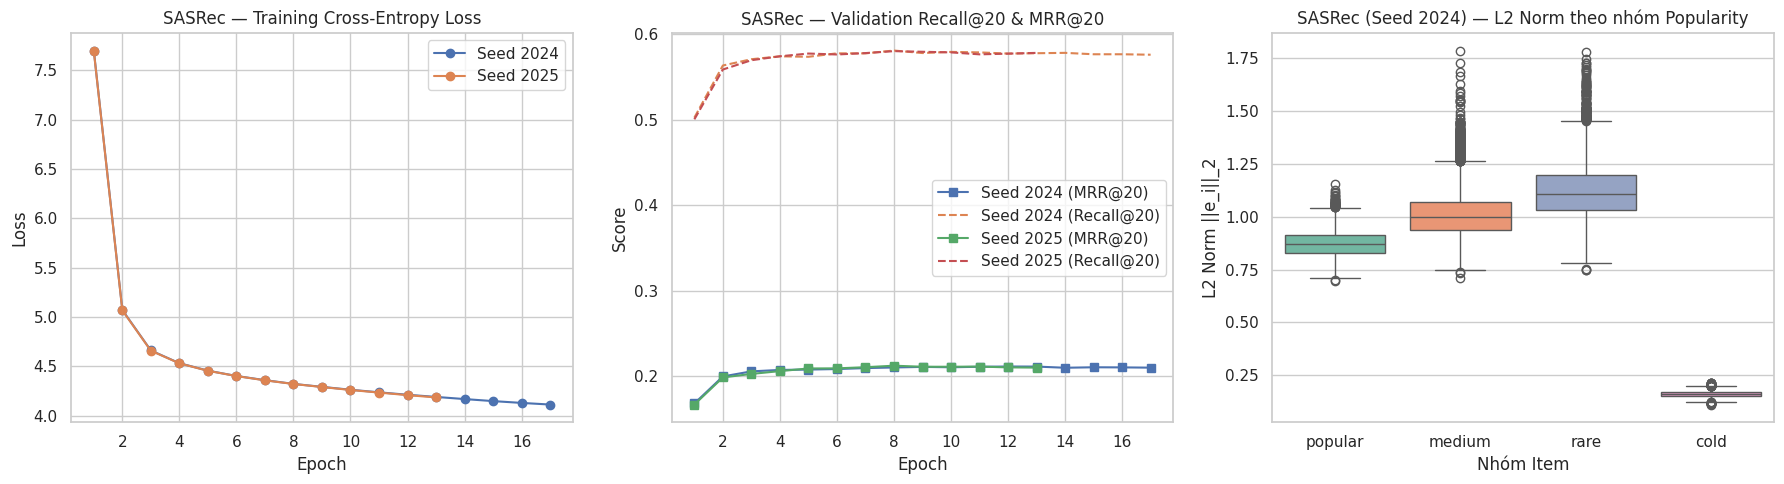

,seed,file,exists,size_kb
0,2024,config.yaml,True,3.4300
1,2024,checkpoint.pth,True,"9,853.9300"
2,2024,training.log,True,4.0100
3,2024,training_history.csv,True,2.1300
4,2024,test_metrics.json,True,4.8600
5,2024,top20.parquet,True,"6,366.3400"
6,2024,item_embeddings.npy,True,"9,395.8800"
7,2024,item_embedding_mapping.csv,True,"2,029.4900"
8,2025,config.yaml,True,3.4300
9,2025,checkpoint.pth,True,"9,853.9300"


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for seed, out in run_outputs.items():
    hist = out["history_df"]
    axes[0].plot(hist["epoch"], hist["train_loss"], marker="o", label=f"Seed {seed}")
    axes[1].plot(hist["epoch"], hist["validation_mrr@20"], marker="s", label=f"Seed {seed} (MRR@20)")
    axes[1].plot(hist["epoch"], hist["validation_recall@20"], linestyle="--", label=f"Seed {seed} (Recall@20)")

axes[0].set_title("SASRec — Training Cross-Entropy Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].set_title("SASRec — Validation Recall@20 & MRR@20")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()

first_seed = CONFIG["seeds"][0]
il_df = run_outputs[first_seed]["item_level_df"]
sns.boxplot(
    data=il_df,
    x="popularity_group",
    y="embedding_norm",
    order=["popular", "medium", "rare", "cold"],
    palette="Set2",
    ax=axes[2],
)
axes[2].set_title(f"SASRec (Seed {first_seed}) — L2 Norm theo nhóm Popularity")
axes[2].set_xlabel("Nhóm Item")
axes[2].set_ylabel("L2 Norm ||e_i||_2")

plt.tight_layout()
plt.show()

REQUIRED_FILES = [
    "config.yaml",
    "checkpoint.pth",
    "training.log",
    "training_history.csv",
    "test_metrics.json",
    "top20.parquet",
    "item_embeddings.npy",
    "item_embedding_mapping.csv",
]

manifest_rows = []
for seed, out in run_outputs.items():
    rdir = out["run_dir"]
    for fname in REQUIRED_FILES:
        fpath = rdir / fname
        manifest_rows.append({
            "seed": seed,
            "file": fname,
            "exists": fpath.is_file(),
            "size_kb": round(fpath.stat().st_size / 1024.0, 2) if fpath.is_file() else 0.0,
        })

manifest_df = pd.DataFrame(manifest_rows)
assert manifest_df["exists"].all(), "Thiếu file bàn giao trong runs/sasrec!"
display(manifest_df)

In [9]:
# ========================================================================
# 8. Đóng gói toàn bộ artifacts huấn luyện SASRec thành sasrec_outputs.zip
# ========================================================================
import zipfile
from pathlib import Path

output_zip = Path('/kaggle/working/sasrec_outputs.zip')
print('Bắt đầu đóng gói kết quả huấn luyện SASRec vào:', output_zip)
with zipfile.ZipFile(output_zip, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for f in sorted(Path('runs/sasrec').rglob('*')):
        if f.is_file() and not f.name.endswith('.gitkeep'):
            zf.write(f, f.as_posix())
            print(f'  + {f.as_posix()} ({f.stat().st_size / 1024:.1f} KB)')
    for f in sorted(Path('results/item_level').glob('sasrec_*.parquet')):
        if f.is_file():
            zf.write(f, f.as_posix())
            print(f'  + {f.as_posix()} ({f.stat().st_size / 1024:.1f} KB)')

print(f'\nĐã đóng gói thành công: {output_zip} ({output_zip.stat().st_size / (1024*1024):.2f} MB)')


Bắt đầu đóng gói kết quả huấn luyện SASRec vào: /kaggle/working/sasrec_outputs.zip
  + runs/sasrec/seed_2024/checkpoint.pth (9853.9 KB)
  + runs/sasrec/seed_2024/config.yaml (3.4 KB)
  + runs/sasrec/seed_2024/item_embedding_mapping.csv (2029.5 KB)
  + runs/sasrec/seed_2024/item_embeddings.npy (9395.9 KB)
  + runs/sasrec/seed_2024/test_metrics.json (4.9 KB)
  + runs/sasrec/seed_2024/top20.parquet (6366.3 KB)
  + runs/sasrec/seed_2024/training.log (4.0 KB)
  + runs/sasrec/seed_2024/training_history.csv (2.1 KB)
  + runs/sasrec/seed_2025/checkpoint.pth (9853.9 KB)
  + runs/sasrec/seed_2025/config.yaml (3.4 KB)
  + runs/sasrec/seed_2025/item_embedding_mapping.csv (2029.5 KB)
  + runs/sasrec/seed_2025/item_embeddings.npy (9395.9 KB)
  + runs/sasrec/seed_2025/test_metrics.json (4.9 KB)
  + runs/sasrec/seed_2025/top20.parquet (6366.1 KB)
  + runs/sasrec/seed_2025/training.log (3.4 KB)
  + runs/sasrec/seed_2025/training_history.csv (1.7 KB)
  + results/item_level/sasrec_seed2024.parquet (1497.